# Discrete and smeared stringers: integrally stiffened Technion shells (Weller and Singer 1977; Poorveis and Kabir 2006)

How far is a model with discrete stringers from the smeared-stiffener theory
when the stringers are closely spaced? Weller and Singer [1] tested in axial
compression integrally stringer-stiffened 7075-T6 shells with the stringers
outside and give, for each shell, the non-dimensional stringer properties,
the load of the linear smeared-stiffener theory for the simple supports SS3
($w = M_x = N_x = v = 0$) and SS4 ($w = M_x = u = v = 0$) and the test load
(Table 1, p. 723). Poorveis and Kabir [2] analysed one of these shells
(AS-27M2, their case A) and a shell of Shen, Zhou and Chen (case D, test
from [3]) with a geometrically nonlinear Ritz model, with discrete and with
smeared stringers (Table 2, p. 119). This notebook builds the shells as
`MultiDomain` assemblies with discrete blade stringers and compares with
these values, and with the smeared theory of Block, Card and Mikulas [4]
(equation (15), SS3, membrane pre-buckling state) evaluated for the section of
[1] (which reproduces the SS3 loads of [1]) and for the section of the
discrete model (the reference of the **discreteness gap**).

The AS-27 shells have a Koiter parameter $\theta > 0.64$, chosen by Weller and
Singer to study unstable postbuckling of the skin panels between the
stringers (p. 722); for AS-27M2 Poorveis and Kabir found the discrete value
30 % below the smeared one and attributed it to panel instability (p. 119).

[1] T. Weller and J. Singer, *Experimental studies on the buckling under
axial compression of integrally stringer-stiffened circular cylindrical
shells*, J. Appl. Mech. 44(4), 721-730, 1977, doi:10.1115/1.3424163.

[2] D. Poorveis and M. Z. Kabir, *Buckling of discretely stringer-stiffened
composite cylindrical shells under combined axial compression and external
pressure*, Scientia Iranica 13(2), 113-123, 2006.

[3] H.-S. Shen, P. Zhou and T.-Y. Chen, *Postbuckling analysis of stiffened
cylindrical shells under combined external pressure and axial compression*,
Thin-Walled Struct. 15, 43-63, 1993, doi:10.1016/0263-8231(93)90012-Y (cited
through [2]; not read).

[4] D. L. Block, M. F. Card and M. M. Mikulas, Jr., *Buckling of eccentrically
stiffened orthotropic cylinders*, NASA TN D-2960, 1965,
https://ntrs.nasa.gov/citations/19650021133.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import blade_cylinder_utils as bu
import stringer_cylinder_utils as su


def pct(value, ref):
    return 100*(value/ref - 1)


def table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    display(Markdown('\n'.join(out)))

def plot_mode(ax, md_, c, skin, R, title, ns, frac=1.):
    x, th, w = bu.skin_w(md_, c, skin, R)
    sel = th <= frac*th.max() + 1e-12
    ax.pcolormesh(np.degrees(th[sel]), x, (w[sel]/np.abs(w).max()).T, cmap='RdBu_r',
                  shading='auto', vmin=-1, vmax=1)
    pos = (np.arange(ns) + 0.5)*2*np.pi/ns
    pos = pos[pos <= th[sel].max()]
    ax.plot(np.degrees(pos), np.zeros_like(pos), 'k.', ms=3)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(r'$\theta$, deg')

## Shells, geometry and material

Table 1 of [1] (p. 723): skin thickness $h$, $R/h$, $L/R$, $-(e_1/h)$ ($e_1$
negative outside, Fig. 1), $A_1/(bh)$, $I_{11}/(bh^3)$ (about the centroid
of the stringer), $\eta_{t1} = G_1 I_{t1}/(bD)$ with $D = E h^3/(12(1 -
\nu^2))$, Koiter's parameter $\theta = [12(1 - \nu^2)]^{1/4} (b/2\pi)
(Rh)^{-1/2}$ (p. 722), the SS3 and SS4 smeared loads and the test load, in
kg (kilogram-force). $E = 0.75 \times 10^4$ kg/mm$^2$ (p. 724), $\nu = 0.30$
(p. 722). The spacing $b$ follows from $\theta$; $2\pi R/b$ gives the
number of stringers. Units here: mm and kg (force); $\bar{N}$ in kg/mm
(times 9.807 for N/mm). AS-26M1 to AS-26M3 are excluded, as by the authors
(footnote b); the SS4 load of AS-35 is misprinted (460 kg; $2850/0.610 = 4672$
kg from the printed ratio) and not used. The stringers are rectangles $t_s
\times h_s$: $h_s = \sqrt{12 I_{11}/A_1}$ reproduces $e_1 = (h + h_s)/2$ and
the torsion constant of the rectangle reproduces $I_{t1}$ (see the
bfsccylinder implementation of this case for the check).

In [2]:
E, NU, KGF = 0.75e4, 0.30, 9.80665
TABLE1 = {
    'AS-27M1': (0.195, 618, 0.648, 3.86, 0.760, 2.860, 23.50, 0.807, 4190, 3600),
    'AS-27M2': (0.204, 591, 0.652, 3.67, 0.717, 2.400, 19.84, 0.789, 4210, 3300),
    'AS-27M3': (0.202, 597, 0.650, 3.72, 0.729, 2.520, 20.83, 0.793, 4240, 3920),
    'AS-34': (0.254, 472, 1.080, 2.97, 0.533, 1.080, 5.75, 0.470, 3430, 2800),
    'AS-35': (0.250, 480, 1.080, 3.04, 0.549, 1.180, 6.11, 0.474, 3390, 2850),
}
# Poorveis and Kabir (2006), Table 1 (p. 119): L, R, h, n_s, A1/(b1 h), e1/h, I1/(b h^3), G1 J1/(b D)
# and Table 2: test, smeared, discrete (kg/mm)
POORVEIS_D = (130.00, 120.10, 0.254, 85, 0.590, 3.420, 1.680, 6.563)
POORVEIS_T2 = {'A': (4.356, 6.110, 4.250), 'D': (5.334, 5.370, 5.450)}
k4 = (12*(1 - NU**2))**0.25
G = E/(2*(1 + NU))


def shell(h, R, L, ns, A, I, e, J, P3=None, Pe=None):
    d = dict(h=h, R=R, L=L, ns=ns, b=2*np.pi*R/ns, A=A, I=I, e=e, J=J, P3=P3, Pe=Pe)
    d['hs'] = np.sqrt(12*I/A)
    d['ts'] = A/d['hs']
    d['Hs'] = d['hs'] + h/2
    d['Jplate'] = d['Hs']*d['ts']**3/3
    return d


shells = {}
rows = []
for s, (h, Rh, LR, e, Ab, Ib, eta, theta, P3, Pe) in TABLE1.items():
    R = Rh*h
    ns = int(round(2*np.pi*R/(theta*2*np.pi*np.sqrt(R*h)/k4)))
    b = 2*np.pi*R/ns
    D = E*h**3/(12*(1 - NU**2))
    shells[s] = shell(h, R, LR*R, ns, Ab*b*h, Ib*b*h**3, e*h, eta*b*D/G, P3, Pe)
L, R, h, ns, Ab, e, Ib, eta = POORVEIS_D
b = 2*np.pi*R/ns
shells['D'] = shell(h, R, L, ns, Ab*b*h, Ib*b*h**3, e*h, eta*b*E*h**3/(12*(1 - NU**2))/G)
for s, d in shells.items():
    rows.append([s, '%.3f' % d['h'], '%.2f' % d['R'], '%.2f' % d['L'], d['ns'], '%.3f' % d['ts'],
                 '%.3f' % d['hs'], '%.4f (%.4f)' % ((d['h'] + d['hs'])/2, d['e']),
                 '%.3f' % d['J'], '%.2f' % (d['J']/d['Jplate'])])
table(['shell', 'h, mm', 'R, mm', 'L, mm', 'n_s', 't_s, mm', 'h_s, mm', '(h + h_s)/2 (e_1), mm',
       'I_t1, mm^4', 'I_t1/J_plate'], rows)

| shell | h, mm | R, mm | L, mm | n_s | t_s, mm | h_s, mm | (h + h_s)/2 (e_1), mm | I_t1, mm^4 | I_t1/J_plate |
|---|---|---|---|---|---|---|---|---|---|
| AS-27M1 | 0.195 | 120.51 | 78.09 | 56 | 1.529 | 1.310 | 0.7527 (0.7527) | 0.561 | 0.33 |
| AS-27M2 | 0.204 | 120.56 | 78.61 | 56 | 1.530 | 1.293 | 0.7485 (0.7487) | 0.542 | 0.33 |
| AS-27M3 | 0.202 | 120.59 | 78.39 | 56 | 1.532 | 1.301 | 0.7515 (0.7514) | 0.553 | 0.33 |
| AS-34 | 0.254 | 119.89 | 129.48 | 84 | 0.969 | 1.252 | 0.7532 (0.7544) | 0.201 | 0.48 |
| AS-35 | 0.250 | 120.00 | 129.60 | 84 | 0.970 | 1.270 | 0.7598 (0.7600) | 0.204 | 0.48 |
| D | 0.254 | 120.10 | 130.00 | 85 | 0.896 | 1.485 | 0.8694 (0.8687) | 0.227 | 0.59 |

## Smeared-stiffener theory

Equation (15) of [4] (`su.smeared_ss`, minimum over $m \le 12$, $n \le 60$)
with the section of [1] reproduces the SS3 loads of [1]. The discrete model
represents a stringer by a plate strip from the middle surface of the skin to
the tip, $t_s \times H_s$, $H_s = h_s + h/2$; as a smeared section this strip
has $A = t_s H_s$, $\bar{z} = H_s/2$, $I_o = t_s H_s^3/3$ and the twisting
stiffness of a Kirchhoff plate strip $4 D_{66} H_s = G H_s t_s^3/3$
("plate J"), 2 to 3 times $G I_{t1}$ for these squat stringers. The main
model scales $D_{66}$ of the blades so that $4 D_{66} H_s = G I_{t1}$
("matched J"); both are run.

In [3]:
rows = []
for s, d in shells.items():
    Wsec = (d['A'], d['e'], d['I'] + d['A']*d['e']**2)
    Psec = (d['ts']*d['Hs'], d['Hs']/2, d['ts']*d['Hs']**3/3)
    d['sm_W'] = su.smeared_ss(d['R'], d['L'], d['h'], E, NU, d['b'], *Wsec, d['J'])
    d['sm'] = {'matched': su.smeared_ss(d['R'], d['L'], d['h'], E, NU, d['b'], *Psec, d['J']),
               'plate': su.smeared_ss(d['R'], d['L'], d['h'], E, NU, d['b'], *Psec, d['Jplate'])}
    N3 = d['P3']/(2*np.pi*d['R']) if d['P3'] else None
    rows.append([s, '-' if N3 is None else '%.3f' % N3,
                 '%.3f %s' % d['sm_W'] + ('' if N3 is None else ', %+.2f %%' % pct(d['sm_W'][0], N3)),
                 '%.3f %s' % d['sm']['matched'], '%.3f %s' % d['sm']['plate']])
table(['shell', 'SS3 of [1], kg/mm', 'Eq. (15), section of [1]', 'Eq. (15), strip, matched J',
       'Eq. (15), strip, plate J'], rows)

| shell | SS3 of [1], kg/mm | Eq. (15), section of [1] | Eq. (15), strip, matched J | Eq. (15), strip, plate J |
|---|---|---|---|---|
| AS-27M1 | 5.534 | 5.540 (1, 13), +0.11 % | 5.555 (1, 13) | 7.998 (1, 11) |
| AS-27M2 | 5.558 | 5.557 (1, 13), -0.01 % | 5.574 (1, 13) | 8.037 (1, 11) |
| AS-27M3 | 5.596 | 5.589 (1, 13), -0.11 % | 5.607 (1, 13) | 8.068 (1, 11) |
| AS-34 | 4.553 | 4.547 (1, 11), -0.14 % | 4.582 (1, 11) | 5.171 (1, 11) |
| AS-35 | 4.496 | 4.491 (1, 11), -0.11 % | 4.527 (1, 11) | 5.122 (1, 11) |
| D | - | 5.018 (1, 11) | 5.052 (1, 11) | 5.486 (1, 11) |

## Model with discrete stringers

`su.buckling_membrane`: the assembly of `bu.build_cylinder`, curved skin
panels `cylshell_clpt_sanders` between the stringers and one `plate_clpt_gl`
blade per stringer (`'SSycte'` and `'BFycte'` connections); the half cylinder
between two symmetry planes through the middle of a bay for an even number of
stringers, the whole cylinder for case D (85 stringers). SS3 ends ($v = w =
0$ on skin and blades, $u$ free, one point with $u = 0$), membrane
pre-buckling state of a uniform axial strain in skin and blades, as in the
smeared theory; ten eigenvalues, the lowest positive one is critical, its
$(m, n)$ from the normal displacement of the skin (`bu.classify`).

## Convergence

Terms $m_x$ along $x$ (skin and blades), $n_y$ across a skin bay and $n_b$
across a blade, matched $J$.

In [4]:
LEVELS = [(12, 6, 4), (16, 8, 4), (20, 10, 5)]
t0 = time.time()
rows = []
for s in ('AS-27M2', 'AS-34'):
    d = shells[s]
    prev = None
    for lev in LEVELS:
        N, modes, N1, md_, skin, ndof, dt = su.buckling_membrane(
            d['R'], d['h'], d['L'], E, NU, d['ts'], d['Hs'], 'external', 'SS', d['ns'], *lev,
            D66_factor=d['J']/d['Jplate'])
        rows.append([s, lev, ndof, '%.1f' % dt, '%.4f' % N, '(%d, %d)' % modes[0][1:3],
                     '' if prev is None else '%+.2f %%' % pct(N, prev)])
        prev = N
table(['shell', 'm_x, n_y, n_b', 'dofs', 'time, s', 'N, kg/mm', '(m, n)', 'change'], rows)
print('%.0f s' % (time.time() - t0))

| shell | m_x, n_y, n_b | dofs | time, s | N, kg/mm | (m, n) | change |
|---|---|---|---|---|---|---|
| AS-27M2 | (12, 6, 4) | 7687 | 8.5 | 4.7175 | (8, 28) |  |
| AS-27M2 | (16, 8, 4) | 12767 | 22.4 | 4.5795 | (9, 28) | -2.93 % |
| AS-27M2 | (20, 10, 5) | 20943 | 37.9 | 4.5365 | (9, 28) | -0.94 % |
| AS-34 | (12, 6, 4) | 11495 | 5.0 | 4.5123 | (1, 11) |  |
| AS-34 | (16, 8, 4) | 19151 | 13.3 | 4.5082 | (1, 11) | -0.09 % |
| AS-34 | (20, 10, 5) | 31415 | 20.9 | 4.5044 | (1, 11) | -0.08 % |

108 s


## Discrete against smeared stringers and the tests

Finest level; "gap" is the discrete model against equation (15) for the same
strip and twisting stiffness.

In [5]:
t0 = time.time()
RES = {}
for s, d in shells.items():
    for J in ('matched', 'plate'):
        f = d['J']/d['Jplate'] if J == 'matched' else 1.
        RES[(s, J)] = su.buckling_membrane(d['R'], d['h'], d['L'], E, NU, d['ts'], d['Hs'],
                                           'external', 'SS', d['ns'], *LEVELS[-1], D66_factor=f)
print('%.0f s' % (time.time() - t0))
rows = []
for s, d in shells.items():
    for J in ('matched', 'plate'):
        N, modes = RES[(s, J)][:2]
        sm = d['sm'][J]
        row = [s, J, '%.3f (%d, %d)' % (N, *modes[0][1:3]), '%.3f' % sm[0], '**%+.1f %%**' % pct(N, sm[0])]
        if d['P3']:
            N3, Ne = d['P3']/(2*np.pi*d['R']), d['Pe']/(2*np.pi*d['R'])
            row += ['%.3f' % N3, '%+.1f %%' % pct(N, N3), '%.3f' % Ne, '%+.1f %%' % pct(N, Ne)]
        else:
            row += ['-', '-', '-', '-']
        rows.append(row)
table(['shell', 'J', 'discrete N (m, n)', 'Eq. (15), same strip', 'gap', 'SS3 of [1]', 'vs SS3',
       'test [1]', 'vs test'], rows)
rows = []
for case, s in (('A', 'AS-27M2'), ('D', 'D')):
    test, sm2, di2 = POORVEIS_T2[case]
    N = RES[(s, 'matched')][0]
    rows.append([case, test, sm2, di2, '%+.1f %%' % pct(di2, sm2), '%.3f' % N, '%+.1f %%' % pct(N, test),
                 '%+.1f %%' % pct(N, di2), '%+.1f %%' % pct(N, sm2), '%.3f' % RES[(s, 'plate')][0]])
table(['case [2]', 'test', 'smeared [2]', 'discrete [2]', 'discrete vs smeared [2]',
       'discrete, matched J', 'vs test', 'vs discrete [2]', 'vs smeared [2]', 'discrete, plate J'], rows)

421 s


| shell | J | discrete N (m, n) | Eq. (15), same strip | gap | SS3 of [1] | vs SS3 | test [1] | vs test |
|---|---|---|---|---|---|---|---|---|
| AS-27M1 | matched | 4.131 (9, 28) | 5.555 | **-25.6 %** | 5.534 | -25.3 % | 4.754 | -13.1 % |
| AS-27M1 | plate | 4.170 (9, 28) | 7.998 | **-47.9 %** | 5.534 | -24.6 % | 4.754 | -12.3 % |
| AS-27M2 | matched | 4.536 (9, 28) | 5.574 | **-18.6 %** | 5.558 | -18.4 % | 4.356 | +4.1 % |
| AS-27M2 | plate | 4.586 (9, 28) | 8.037 | **-42.9 %** | 5.558 | -17.5 % | 4.356 | +5.3 % |
| AS-27M3 | matched | 4.449 (9, 28) | 5.607 | **-20.6 %** | 5.596 | -20.5 % | 5.173 | -14.0 % |
| AS-27M3 | plate | 4.495 (9, 28) | 8.068 | **-44.3 %** | 5.596 | -19.7 % | 5.173 | -13.1 % |
| AS-34 | matched | 4.504 (1, 11) | 4.582 | **-1.7 %** | 4.553 | -1.1 % | 3.717 | +21.2 % |
| AS-34 | plate | 5.005 (1, 11) | 5.171 | **-3.2 %** | 4.553 | +9.9 % | 3.717 | +34.7 % |
| AS-35 | matched | 4.448 (1, 11) | 4.527 | **-1.7 %** | 4.496 | -1.1 % | 3.780 | +17.7 % |
| AS-35 | plate | 4.952 (1, 11) | 5.122 | **-3.3 %** | 4.496 | +10.1 % | 3.780 | +31.0 % |
| D | matched | 4.957 (1, 11) | 5.052 | **-1.9 %** | - | - | - | - |
| D | plate | 5.320 (1, 11) | 5.486 | **-3.0 %** | - | - | - | - |

| case [2] | test | smeared [2] | discrete [2] | discrete vs smeared [2] | discrete, matched J | vs test | vs discrete [2] | vs smeared [2] | discrete, plate J |
|---|---|---|---|---|---|---|---|---|---|
| A | 4.356 | 6.11 | 4.25 | -30.4 % | 4.536 | +4.1 % | +6.7 % | -25.8 % | 4.586 |
| D | 5.334 | 5.37 | 5.45 | +1.5 % | 4.957 | -7.1 % | -9.0 % | -7.7 % | 5.320 |

**Buckling modes** (matched $J$): normal displacement of the skin, unrolled;
AS-27M2 over one sixth of the half cylinder modelled, AS-34 over the half
cylinder; the dots mark the stringers.

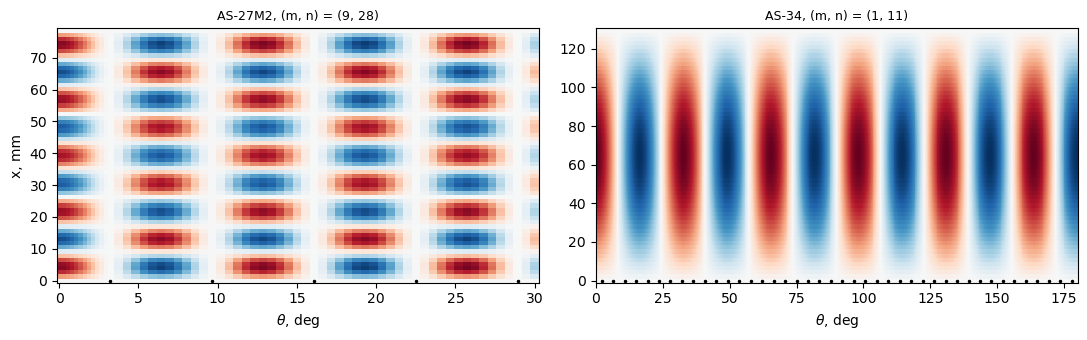

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, s, frac in ((axes[0], 'AS-27M2', 1/6), (axes[1], 'AS-34', 1.)):
    N, modes, N1, md_, skin = RES[(s, 'matched')][:5]
    plot_mode(ax, md_, modes[0][3], skin, shells[s]['R'],
              '%s, (m, n) = (%d, %d)' % (s, *modes[0][1:3]), shells[s]['ns'], frac)
axes[0].set_ylabel('x, mm')
plt.tight_layout()
plt.show()

**Case B** of [2] is cylinder 1 of Card and Jones (1966),
`card1966_blade_cylinder_buckling.ipynb`; case C is loaded by external
pressure and is not modelled.

## Discussion

- **Input.** Equation (15) of [4] with the stringer properties of Table 1 of
  [1] reproduces the SS3 loads of [1] within 0.14 % for the five shells, so
  the section, the material and the number of stringers are read as Weller
  and Singer read them. The stringers are rectangles; their torsion constant
  $I_{t1}$ is that of the rectangle.
- **General instability (AS-34, AS-35, case D; $\theta = 0.47$, $b/\sqrt{Rh}
  = 1.6$).** The discrete model buckles in the general mode $(m, n) = (1,
  11)$ of the smeared theory, 1.7 % below equation (15) for the same
  plate strip with the matched twisting stiffness (3.2 to 3.3 % with the
  plate twisting stiffness). This is the discreteness gap at this spacing: one
  to two percent. Against the SS3 loads of [1] (for the rectangle) the
  discrete model is 1.1 % below; the overlap of the strip with the skin and its
  centroid at $H_s/2$ instead of $e_1$ make equation (15) for the strip 0.8 %
  higher than for the rectangle. The tests are at 82 and 84 % of SS3
  (the "linearity" of [1]), +18 and +21 % from the discrete model: the
  difference between test and theory is the imperfection sensitivity
  discussed in [1], not the discreteness of the stringers.
- **Panel instability (AS-27; $\theta = 0.79$ to 0.81).** The lowest mode of
  the discrete model is local: the skin between the stringers buckles with
  one half-wave per bay ($n = n_s/2 = 28$) and nine axial half-waves, at
  4.13 to 4.54 kg/mm, 18.6 to 25.6 % below the general instability of the smeared
  theory, which cannot represent this mode. This is the case of a large
  "gap" in the literature: Poorveis and Kabir found their discrete value 30 %
  below their smeared one for AS-27M2 and attributed it to panel instability
  ([2], p. 119). The discrete model of this notebook is +4.1 % from the
  test of AS-27M2 and +6.7 % from the discrete value of [2] (whose model
  includes the nonlinear pre-buckling deformation and transverse shear); the
  three tests of the nearly equal AS-27 shells scatter from 4.36 to 5.17
  kg/mm, and the model is -13.1, +4.1 and -14.0 % from them. The local load is almost
  independent of the twisting stiffness of the stringers (+0.9 to +1.1 % from
  matched to plate $J$), whereas the general-instability load of the smeared
  theory rises by 44 % with the plate twisting stiffness: with an unmatched
  plate strip the apparent gap would be 43 to 48 %. In the model the skin
  bay is the whole pitch $b = 13.5$ mm, the stringer root being a line; the
  real stringers are 1.53 mm wide (11 % of the pitch), which leaves a
  narrower skin panel and would raise the local load (a plate-buckling load
  scales with the inverse square of the panel width: $(13.53/12.0)^2 = 1.27$
  for the free width, an estimate, not a computed value).
- **Case D of [2]** (85 stringers, from Shen, Zhou and Chen [3]): discrete
  4.957 kg/mm, -1.9 % from equation (15) for the same strip, -7.1 %
  from the test of [3] cited by [2]. Poorveis and Kabir give the discrete
  value 1.5 % *above* the smeared one (5.450 and 5.370 kg/mm); their smeared
  nonlinear value is 7 % above equation (15) with their own section (5.018
  kg/mm), so the difference between their two models and the linear theory
  is larger than the discreteness effect found here. Case B of [2] (cylinder
  1 of Card and Jones, discrete 5.2 % above smeared in [2]): both
  implementations of the card1966 notebooks give the discrete simply
  supported membrane load within 0.1 % of the smeared $\bar{N}_s$.
- **Summary of the gap.** With closely spaced stringers that buckle in a
  general mode, the discrete model is 1 to 2 % below the smeared theory of
  the same section; when the skin between the stringers is prone to panel
  buckling ($\theta > 0.64$), the discrete model buckles locally, 19 to 26 %
  below the smeared general instability. Weller and Singer write that the
  discreteness "has also been studied and found to be negligible for closely
  spaced stiffened cylinders except for unusual geometries" (p. 722); the
  AS-27 shells are such a geometry by design.
- **The bfsccylinder implementation of this case**
  (`bfsccylinder/notebooks/weller1977_stiffened_cylinder_buckling.ipynb`:
  one stringer pitch with cyclic symmetry, `BFSCCylinderSanders` skin and
  `BFSCPlate2D` stringer, every harmonic $n \le n_s/2$, the same strips) gives
  the same modes and agrees within 0.7 %: AS-27M1/M2/M3 4.134, 4.540, 4.453
  kg/mm (here 4.131, 4.536, 4.449); AS-34 and AS-35 4.526 and 4.470 (here
  4.504 and 4.448); case D 4.988 (here 4.957). Its gaps are -1.2 % (AS-34,
  AS-35) and -1.3 % (case D) with the matched $J$. It also checks that the
  rectangle $t_s \times h_s$ reproduces $e_1$ and $I_{t1}$ of [1].